# SAINT Model Training & Model Evaluation

Fetching pipeline data splits...
Using active hardware device: cuda
Loss weights configured: Legitimate=0.5050, Fraud=50.1236
Training SAINT Transformer Network... (Mapping multi-feature column blocks)
  epoch    train_loss    valid_acc    valid_loss      dur
-------  ------------  -----------  ------------  -------
      1        0.4679       0.7893        0.5141  22.7051
      2        0.4282       0.7914        0.4981  22.3944
      3        0.4224       0.8008        0.4967  22.3615
      4        0.4162       0.8007        0.4934  22.6227
      5        0.4141       0.7998        0.4863  22.5265
      6        0.4099       0.7822        0.4847  22.0994
      7        0.4084       0.7857        0.4809  22.5615
      8        0.4057       0.7800        0.4790  22.4166
      9        0.4041       0.7779        0.4796  22.2887
     10        0.4033       0.7751        0.4813  22.4486
     11        0.4013       0.7719        0.4808  22.2869
     12        0.3978       0.7639        0.

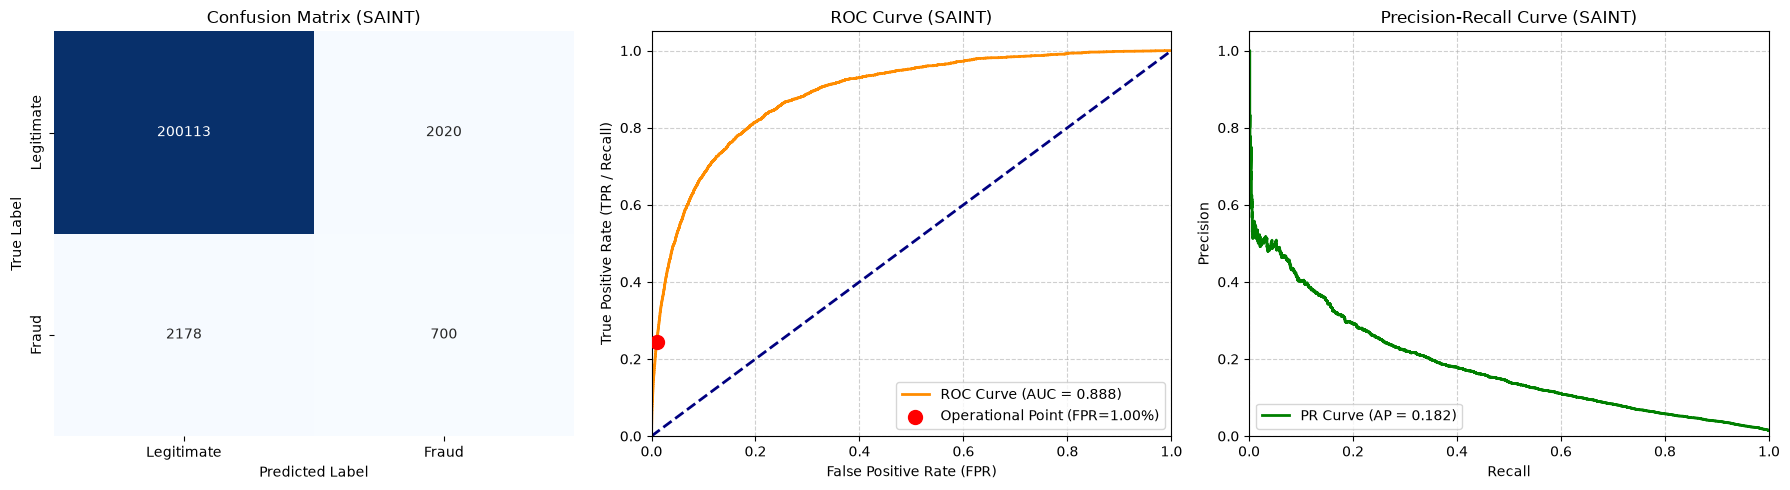

In [ ]:
import sys
import torch
import torch.nn as nn
import numpy as np
from pathlib import Path
from skorch import NeuralNetClassifier
from skorch.callbacks import EarlyStopping

# Setup the project root directory paths safely
PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Import your standardized pipeline and evaluation modules
from src.pipeline import get_data
from src.evaluation import evaluate_predictions

print("Fetching pipeline data splits...")
data = get_data()

X_train = data["X_train_dense"].astype(np.float32)
y_train = data["y_train"].astype(np.int64)
X_val = data["X_val_dense"].astype(np.float32)
y_val = data["y_val"].astype(np.int64)
X_test = data["X_test_dense"].astype(np.float32)
y_test = data["y_test"].astype(np.int64)

# Auto-detect processing device (GPU if available)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using active hardware device: {device}")

# Compute Inverse Frequency Weights for Cross-Entropy Loss Imbalance
class_counts = np.bincount(y_train)
total_samples = len(y_train)
weight_class_0 = total_samples / (2.0 * class_counts[0])
weight_class_1 = total_samples / (2.0 * class_counts[1])
ce_weights_tensor = torch.tensor([weight_class_0, weight_class_1], dtype=torch.float32).to(device)
print(f"Loss weights configured: Legitimate={weight_class_0:.4f}, Fraud={weight_class_1:.4f}")

# OPTIMIZED STANDALONE SAINT TABULAR TRANSFORMER MODULE
class SAINTTabularModule(nn.Module):
    def __init__(self, in_features, d_token=32, n_blocks=2, n_heads=4, dropout=0.1):
        super().__init__()
        self.in_features = in_features
        self.d_token = d_token
        
        # Feature Tokenizer: Vectorized matrix mapping for continuous/encoded columns
        self.tokenizer = nn.Parameter(torch.randn(1, in_features, d_token))
        self.bias = nn.Parameter(torch.zeros(1, in_features, d_token))
        
        # Stacked Column Attention Blocks
        # Alternate layers can be modified here if full sample-row attention is desired
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * 4, 
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.column_transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_blocks)
        
        # Classification Projection Head
        self.ln = nn.LayerNorm(d_token * in_features)
        self.head = nn.Linear(d_token * in_features, 2)

    def forward(self, x):
        # Map raw continuous features to spatial token dimensions
        x = x.unsqueeze(-1) * self.tokenizer + self.bias  # Shape: [Batch, In_Features, d_token]
        
        # Pass features through multi-head column interaction layers
        x = self.column_transformer(x)
        
        # Flatten column maps and evaluate binary distributions [Batch, 2]
        x = x.flatten(start_dim=1)
        x = self.ln(x)
        return self.head(x)

# ==============================================================================
# 3. INITIALIZE AND TRAIN THE NETWORK VIA SKORCH ENGINE
# ==============================================================================
input_dim = X_train.shape[1]

model = NeuralNetClassifier(
    module=SAINTTabularModule,
    module__in_features=input_dim,
    module__d_token=32,          # Embedding projection vector space
    module__n_blocks=2,          # Number of attention transformer layers
    module__n_heads=4,           # Number of parallel attention heads
    criterion=nn.CrossEntropyLoss,
    criterion__weight=ce_weights_tensor,  # Hardware-pinned class weights for 1.1% imbalance
    optimizer=torch.optim.AdamW,
    optimizer__lr=1e-3,
    optimizer__weight_decay=1e-4,
    max_epochs=20,               
    batch_size=4096,             # Scaled batch format for large data constraints
    device=device,
    callbacks=[
        EarlyStopping(patience=5, monitor='valid_loss') # Guards against overfitting loops
    ],
    verbose=1
)

print("Training SAINT Transformer Network... (Mapping multi-feature column blocks)")
model.fit(X_train, y_train)




Generating test predictions...
Running complete evaluation report...
 EVALUATION REPORT: SAINT
Accuracy:                 97.9523%
Fraud precision:          25.7353%
Fraud recall:             24.3224%
Fraud F1:                 25.0089%
PR-AUC (AP):              18.2133%
ROC-AUC:                  88.7876%
Recall @ FPR <= 1.00%:    24.3224%
FPR at chosen threshold:  0.9993%
Chosen Decision Boundary: 0.9276
[Classification Report]
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99    202133
       Fraud       0.26      0.24      0.25      2878

    accuracy                           0.98    205011
   macro avg       0.62      0.62      0.62    205011
weighted avg       0.98      0.98      0.98    205011



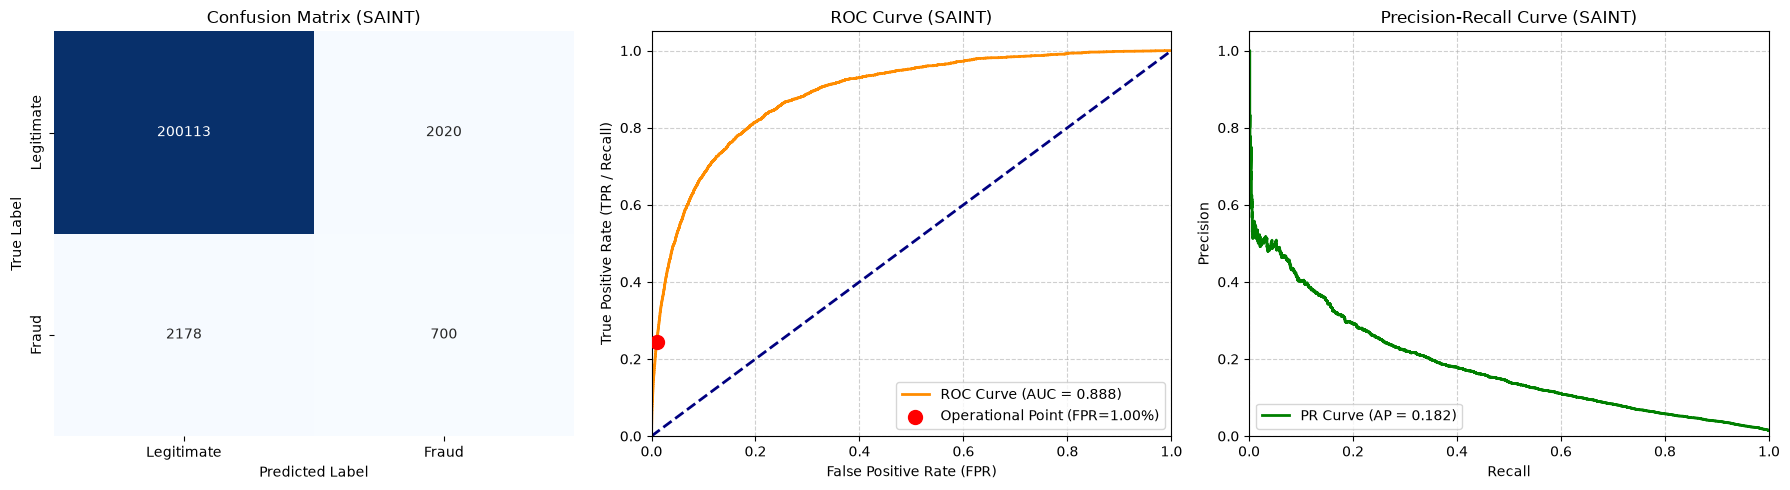

In [3]:
# GENERATE PREDICTIONS AND EVALUATE
print("Generating test predictions...")
test_probabilities = model.predict_proba(X_test)[:, 1]

print("Running complete evaluation report...")
evaluate_predictions(
    y_true=y_test,
    y_probs=test_probabilities,
    model_name="SAINT"
)

In [ ]:
import os

# Create the models directory if it doesn't exist
MODELS_DIR = Path(PROJECT_ROOT) / "models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Save the parameters safely using skorch
saint_save_path = MODELS_DIR / "saint_model.pkl"
model.save_params(f_params=str(saint_save_path))

print(f"SAINT model architecture weights saved to: {saint_save_path}")

SAINT model architecture weights saved to: C:\Users\shubh\projects\FairFraud\models\saint_model.pkl
